# Fitting a ringdown with overtones

From the course [*Black-hole perturbation theory*](https://svykho.github.io/lab/course/) by Alejandro Svyatkovskyy Kholyavka, [Lesson 12: Compute it yourself](https://svykho.github.io/lab/course/compute.html).

When does the ringdown start, and how many modes does it take to describe it? This notebook repeats the experiment of [Lesson 10](https://svykho.github.io/lab/course/sources.html) on a signal where we know the answer: the $\ell = 2$ Regge–Wheeler barrier hit by a wave packet, where linear theory holds at all times and the frequencies are known from Leaver's method ([Lesson 6](https://svykho.github.io/lab/course/quasinormal-modes.html)). It needs NumPy, SciPy and Matplotlib and runs in a few seconds.

Units: $G = c = M = 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## The signal

The same evolution as in the notebook *Ringing a black hole in the time domain*, repeated here so that this notebook stands on its own.

In [2]:
def r_of_rstar(rs):
    return 2 * (1 + lambertw(np.exp(rs / 2 - 1)).real)


def V_rw(r, l):
    return (1 - 2 / r) * (l * (l + 1) / r**2 - 6 / r**3)


def evolve(V, g, x0, x1, dx, T, obs):
    dt = 0.5 * dx
    x = x0 + dx * np.arange(round((x1 - x0) / dx) + 1)
    Vdt2 = V(x) * dt**2
    old, now = g(x - dt), g(x)
    lam, c = (dt / dx) ** 2, dt / dx
    io = round((obs - x0) / dx)
    steps = round(T / dt)
    signal = np.empty(steps + 1)
    signal[0] = now[io]
    for k in range(1, steps + 1):
        new = np.empty_like(now)
        new[1:-1] = 2 * now[1:-1] - old[1:-1] + lam * (now[2:] - 2 * now[1:-1] + now[:-2]) - Vdt2[1:-1] * now[1:-1]
        new[0] = now[0] + c * (now[1] - now[0])
        new[-1] = now[-1] - c * (now[-1] - now[-2])
        old, now = now, new
        signal[k] = now[io]
    return dt * np.arange(steps + 1), signal


def packet(x, x0=50.0, sigma=6.0, nu=0.4):
    z = x - x0
    return np.exp(-z**2 / (2 * sigma**2)) * np.cos(nu * z)


t, psi = evolve(lambda x: V_rw(r_of_rstar(x), 2), packet, -300, 600, 0.2, 430, obs=100)
ip = np.argmax(np.abs(psi))
t = t - t[ip]  # time after the peak from now on
print(f"the signal peaks at t = {-t[0]:.1f}M after the start of the run")

the signal peaks at t = 152.2M after the start of the run


## The model

The quasinormal frequencies of $\ell = 2$, from Leaver's method (Lesson 6):

In [3]:
qnm = np.array([0.373672 - 0.088962j, 0.346711 - 0.273915j, 0.301053 - 0.478277j, 0.251505 - 0.705148j])

The signal is real, so each mode contributes $e^{\operatorname{Im}\omega_n\,(t - t_0)}\left[a_n\cos\operatorname{Re}\omega_n (t - t_0) + b_n\sin\operatorname{Re}\omega_n (t - t_0)\right]$. With the frequencies fixed, the model is **linear** in the amplitudes $a_n, b_n$, so the best fit is a single linear least-squares problem: no initial guess, no iterations, one answer. The amplitude of mode $n$ at the start of the fit is $\sqrt{a_n^2 + b_n^2}$.

In [4]:
def fit_modes(t, y, t0, t1, ws):
    """Least-squares amplitudes of the modes ws in y on t0 <= t <= t1.
    Returns the complex amplitudes at t0 and the fitted curve."""
    m = (t >= t0) & (t <= t1)
    tau = t[m] - t0
    cols = []
    for w in ws:
        e = np.exp(w.imag * tau)
        cols += [e * np.cos(w.real * tau), e * np.sin(w.real * tau)]
    A = np.column_stack(cols)
    c = np.linalg.lstsq(A, y[m], rcond=None)[0]
    return c[0::2] + 1j * c[1::2], t[m], A @ c

Mode amplitudes measured at different start times can only be compared after bringing them to a common time. We extrapolate each one back to the peak, $t = 0$, with its own decay rate, $|A_n(0)| = |A_n(t_0)|\,e^{-\operatorname{Im}\omega_n t_0}$. A mode that is really in the signal gives the same answer whatever $t_0$ is.

In [5]:
END = 140  # every fit ends 140M after the peak


def amplitudes_at_peak(t0, N):
    A, _, _ = fit_modes(t, psi, t0, END, qnm[:N])
    return np.abs(A) * np.exp(-qnm[:N].imag * t0)


late = amplitudes_at_peak(60, 1)[0]  # one mode, fitted late: the reference value
print(f"amplitude of the fundamental mode at the peak, fitted from +60M: {late:.4f}")

amplitude of the fundamental mode at the peak, fitted from +60M: 1.3165


## How many modes?

The fitted amplitude of the fundamental mode, against the start of the fit, for fits with one to four modes. The figure of Lesson 10 is this plot.

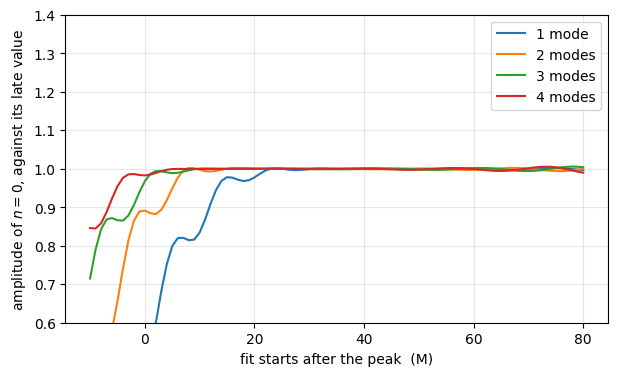

1 mode(s): +0M: 0.469   +5M: 0.799   +10M: 0.834   +15M: 0.978   +25M: 1.000
2 mode(s): +0M: 0.891   +5M: 0.949   +10M: 0.997   +15M: 1.000   +25M: 1.000
3 mode(s): +0M: 0.968   +5M: 0.988   +10M: 1.000   +15M: 1.000   +25M: 1.000
4 mode(s): +0M: 0.983   +5M: 0.999   +10M: 0.999   +15M: 1.000   +25M: 1.000


In [6]:
starts = np.arange(-10, 81, 1)
fig, ax = plt.subplots(figsize=(7, 4))
for N in (1, 2, 3, 4):
    a0 = [amplitudes_at_peak(u, N)[0] / late for u in starts]
    ax.plot(starts, a0, label=f"{N} mode" + ("s" if N > 1 else ""))
ax.set_ylim(0.6, 1.4)
ax.set_xlabel("fit starts after the peak  (M)")
ax.set_ylabel("amplitude of $n = 0$, against its late value")
ax.legend()
plt.show()

for N in (1, 2, 3, 4):
    print(f"{N} mode(s):", "   ".join(f"+{u}M: {amplitudes_at_peak(u, N)[0] / late:.3f}" for u in (0, 5, 10, 15, 25)))

With one mode the fit is wrong by a factor of two at the peak, and settles only $15$ to $25M$ later. Each overtone added lets the fit start earlier.

## Are the overtones real?

Look at the overtones themselves: their amplitudes at the peak, relative to the fundamental mode, for fits with three and four modes.

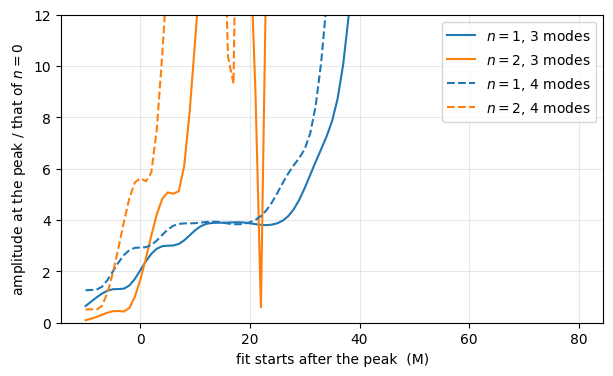

3 modes, n = 1 against n = 0: +10M: 3.60   +15M: 3.89   +20M: 3.87   +25M: 3.88   +40M: 17.65
4 modes, n = 1 against n = 0: +10M: 3.88   +15M: 3.90   +20M: 3.91   +25M: 5.06   +40M: 46.48


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for N, ls in ((3, "-"), (4, "--")):
    r1 = [amplitudes_at_peak(u, N)[1] / amplitudes_at_peak(u, N)[0] for u in starts]
    r2 = [amplitudes_at_peak(u, N)[2] / amplitudes_at_peak(u, N)[0] for u in starts]
    ax.plot(starts, r1, ls, color="C0", label=f"$n = 1$, {N} modes")
    ax.plot(starts, r2, ls, color="C1", label=f"$n = 2$, {N} modes")
ax.set_ylim(0, 12)
ax.set_xlabel("fit starts after the peak  (M)")
ax.set_ylabel("amplitude at the peak / that of $n = 0$")
ax.legend()
plt.show()

for N in (3, 4):
    print(f"{N} modes, n = 1 against n = 0:", "   ".join(f"+{u}M: {amplitudes_at_peak(u, N)[1] / amplitudes_at_peak(u, N)[0]:.2f}" for u in (10, 15, 20, 25, 40)))

The first overtone settles near 3.9 times the fundamental, but only for fits starting between roughly $10M$ and $25M$. Later it has decayed below what is left of the signal, and extrapolating that back to the peak, by a factor $e^{0.27\,t_0}$, blows it up. The second overtone never settles. Even here, with no noise and no nonlinearity, only the fundamental mode is robust.

## The fit and what it leaves

Signal, fit and residual for four modes starting at the peak.

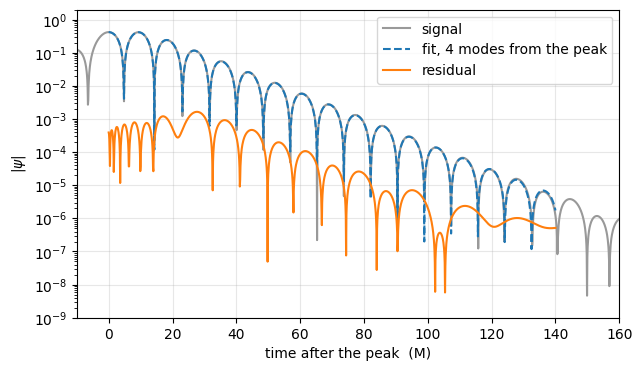

In [8]:
A, tf, yf = fit_modes(t, psi, 0, END, qnm[:4])
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(t, np.abs(psi), color="0.6", label="signal")
ax.semilogy(tf, np.abs(yf), "--", label="fit, 4 modes from the peak")
m = (t >= 0) & (t <= END)
ax.semilogy(t[m], np.abs(psi[m] - yf), label="residual")
ax.set_xlim(-10, 160)
ax.set_ylim(1e-9, 2)
ax.set_xlabel("time after the peak  (M)")
ax.set_ylabel(r"$|\psi|$")
ax.legend()
plt.show()

## Try this

- Free the frequencies: fit $N$ damped sinusoids with unknown complex frequencies using `scipy.optimize.least_squares`, starting near Leaver's values. How stable are the fitted overtone frequencies against the start time?
- Add noise, `psi + 1e-4 * np.random.randn(len(psi))`, and repeat the experiment. Which modes survive?
- Use a packet that does not oscillate, $\nu = 0$. The tail is stronger (Lesson 8); what does it do to the late fits?